In [1]:
library(ArchR)
library(parallel)
library(Seurat)
library(pryr) 
library(dplyr)
addArchRThreads(threads = 16)
set.seed(1)
addArchRGenome("hg38")

载入需要的程辑包：ggplot2

Warning message:
“程辑包‘ggplot2’是用R版本4.1.3 来建造的”
载入需要的程辑包：SummarizedExperiment

载入需要的程辑包：MatrixGenerics

载入需要的程辑包：matrixStats

Warning message:
“程辑包‘matrixStats’是用R版本4.1.3 来建造的”

载入程辑包：‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,


In [2]:
setwd('/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio')

proj <- loadArchRProject(path = "/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Immune_RNA_transfer/ArchRProject_23sample_RNA_transfer_T_B_MY_250819")

Successfully loaded ArchRProject!


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .____

In [3]:
proj


           ___      .______        ______  __    __  .______      
          /   \     |   _  \      /      ||  |  |  | |   _  \     
         /  ^  \    |  |_)  |    |  ,----'|  |__|  | |  |_)  |    
        /  /_\  \   |      /     |  |     |   __   | |      /     
       /  _____  \  |  |\  \\___ |  `----.|  |  |  | |  |\  \\___.
      /__/     \__\ | _| `._____| \______||__|  |__| | _| `._____|
    



class: ArchRProject 
outputDirectory: /media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Immune_RNA_transfer/ArchRProject_23sample_RNA_transfer_T_B_MY_250819 
samples(47): HNM07A3 HNM09H3 ... HNM19A3 HNM19A2
sampleColData names(1): ArrowFiles
cellColData names(60): Sample TSSEnrichment ... subset celltype_l2
numberOfCells(1): 64918
medianTSS(1): 15.363
medianFrags(1): 2404.5

In [4]:
library(FactoMineR)
library(Factoshiny)
library(missMDA)
library(FactoInvestigate)
library("factoextra")
library(mice)
library(ggplot2)
library(ggrepel)


载入需要的程辑包：shiny

Warning message:
“程辑包‘shiny’是用R版本4.1.3 来建造的”
载入需要的程辑包：FactoInvestigate


载入程辑包：‘FactoInvestigate’


The following object is masked from ‘package:Biobase’:

    description


Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa


载入程辑包：‘mice’


The following objects are masked from ‘package:SummarizedExperiment’:

    cbind, rbind


The following objects are masked from ‘package:IRanges’:

    cbind, rbind


The following objects are masked from ‘package:S4Vectors’:

    cbind, rbind


The following objects are masked from ‘package:BiocGenerics’:

    cbind, rbind


The following object is masked from ‘package:stats’:

    filter


The following objects are masked from ‘package:base’:

    cbind, rbind


Warning message:
“程辑包‘ggrepel’是用R版本4.1.3 来建造的”


In [5]:
colnames(proj@cellColData)


[1] "Sample"                 "TSSEnrichment"          "ReadsInTSS"            
 [4] "ReadsInPromoter"        "ReadsInBlacklist"       "PromoterRatio"         
 [7] "PassQC"                 "NucleosomeRatio"        "nMultiFrags"           
[10] "nMonoFrags"             "nFrags"                 "nDiFrags"              
[13] "DoubletScore"           "DoubletEnrichment"      "BlacklistRatio"        
[16] "BioNames"               "sample"                 "cell_barcodes"         
[19] "Group"                  "Age"                    "Sex"                   
[22] "sneezing"               "Runny_nose"             "Itchy_nose"            
[25] "Nasal_congestion"       "Eye_irritation"         "VAS_score"             
[28] "allergic_history"       "Total_IgE"              "Artemisia annua pollen"
[31] "Poplar pollen"          "Elm pollen"             "Willow pollen"         
[34] "Dog fur"                "Cat fur"                "def"                   
[37] "dep"                    "group_a"                "group_A"               
[40] "group"                  "EOS_Count"              "Clusters"              
[43] "Clusters_res_0.1"       "Clusters_res_0.2"       "Clusters_res_0.3"      
[46] "Clusters_res_0.5"       "Clusters_res_0.8"       "celltype"              
[49] "Clusters_0.9"           "predictedCell_Un"       "predictedGroup_Un"     
[52] "predictedScore_Un"      "predictedCell_Co"       "cluster_RNA_transfer"  
[55] "predictedScore_Co"      "barcodes"               "celltype_L2"           
[58] "celltype_L1"            "subset"                 "celltype_l2"

In [6]:
table(proj$celltype_L2)


    B_Cells CD4_T_Cells CD8_T_Cells   Dendritic  Macrophage        Mast 
       2829        5767       38298        2021       10832         752 
   Monocyte      Plasma 
       2709        1710 

In [7]:
table(proj$subset)


Aptypical_Bm      CD14_Mo      CD4_TH1       CD4_Tm      CD4_Trm      CD8_CTL 
         983         2709          658         2488         2621         4076 
     CD8_ISG CD8_Tm_PLCG2       CD8_Tn      CD8_Trm          cDC   Macro_C1QB 
         274        16965         2381        12461         1236          779 
  Macro_CCL3   macro_SLPI  Macro_STAB1   Mast_cells      Naive_B          NKT 
        4749         4248         1056          752          149         2141 
         pDC Plasma_IGHA1 Plasma_IGHG1      Swit_Bm 
         785           60         1650         1697 

In [8]:
library(dplyr)
library(Seurat)  # 确保加载了Seurat包

cellColData <- getCellColData(proj)
cell_col_data <- as.data.frame(cellColData)


# 使用 dplyr 进行操作
Ratio_Sample <- cell_col_data %>%
  group_by(sample, subset) %>%
  summarise(n = n()) %>%
  mutate(relative_freq = n / sum(n))

# 查看结果
print(Ratio_Sample)

# 添加 Group 信息到数据框中
group_info <- cell_col_data %>%
  select(sample, group_A) %>%
  distinct()

# 将 Group 信息合并到 Ratio_Sample 数据框中
Ratio_Sample <- Ratio_Sample %>%
  left_join(group_info, by = "sample")

# 查看结果
print(Ratio_Sample)

# 保存到 CSV 文件
write.csv(Ratio_Sample, "/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio/IMMUNE_cell_PCA_scATAC_Sample_prop_group_by_cell_type_proportions_long.csv", row.names = FALSE)

`summarise()` has grouped output by 'sample'. You can override using the
`.groups` argument.


# A tibble: 487 × 4
# Groups:   sample [23]
   sample subset           n relative_freq
   <chr>  <chr>        <int>         <dbl>
 1 HNM04  Aptypical_Bm   103       0.0482 
 2 HNM04  CD14_Mo         49       0.0229 
 3 HNM04  CD4_TH1         12       0.00561
 4 HNM04  CD4_Tm          84       0.0393 
 5 HNM04  CD4_Trm         67       0.0313 
 6 HNM04  CD8_CTL         93       0.0435 
 7 HNM04  CD8_ISG         16       0.00748
 8 HNM04  CD8_Tm_PLCG2   670       0.313  
 9 HNM04  CD8_Tn          49       0.0229 
10 HNM04  CD8_Trm        278       0.130  
# ℹ 477 more rows
# A tibble: 487 × 5
# Groups:   sample [23]
   sample subset           n relative_freq group_A
   <chr>  <chr>        <int>         <dbl> <chr>  
 1 HNM04  Aptypical_Bm   103       0.0482  MAR    
 2 HNM04  CD14_Mo         49       0.0229  MAR    
 3 HNM04  CD4_TH1         12       0.00561 MAR    
 4 HNM04  CD4_Tm          84       0.0393  MAR    
 5 HNM04  CD4_Trm         67       0.0313  MAR    
 6 HNM04  CD8_CTL    

In [9]:
# 删除列 n（假设 n 是第 3 列）
Ratio_Sample <- Ratio_Sample[,-3]

# 查看结果
print(Ratio_Sample)

# A tibble: 487 × 4
# Groups:   sample [23]
   sample subset       relative_freq group_A
   <chr>  <chr>                <dbl> <chr>  
 1 HNM04  Aptypical_Bm       0.0482  MAR    
 2 HNM04  CD14_Mo            0.0229  MAR    
 3 HNM04  CD4_TH1            0.00561 MAR    
 4 HNM04  CD4_Tm             0.0393  MAR    
 5 HNM04  CD4_Trm            0.0313  MAR    
 6 HNM04  CD8_CTL            0.0435  MAR    
 7 HNM04  CD8_ISG            0.00748 MAR    
 8 HNM04  CD8_Tm_PLCG2       0.313   MAR    
 9 HNM04  CD8_Tn             0.0229  MAR    
10 HNM04  CD8_Trm            0.130   MAR    
# ℹ 477 more rows


In [11]:
library(tidyr)
library(dplyr)

# 使用 pivot_wider 将数据从长格式转换为宽格式
df_wide <- Ratio_Sample %>%
  pivot_wider(names_from = subset, values_from = relative_freq)

# 查看转换后的数据框
print(df_wide)

# A tibble: 23 × 24
# Groups:   sample [23]
   sample group_A Aptypical_Bm  CD14_Mo CD4_TH1 CD4_Tm CD4_Trm CD8_CTL   CD8_ISG
   <chr>  <chr>          <dbl>    <dbl>   <dbl>  <dbl>   <dbl>   <dbl>     <dbl>
 1 HNM04  MAR          0.0482   0.0229  0.00561 0.0393  0.0313  0.0435  0.00748 
 2 HNM05  MAR         NA       NA       0.00201 0.0329  0.0116  0.0578  0.0293  
 3 HNM07  MAR          0.0241   0.0186  0.0181  0.0522  0.0873  0.0361  0.0115  
 4 HNM09  NAR          0.134    0.0279  0.00288 0.0183  0.0173  0.0394  0.00288 
 5 HNM10  NAR          0.00219  0.237   0.00612 0.0214  0.0232  0.0665  0.0144  
 6 HNM14  MAR          0.0118   0.0438  0.00355 0.0367  0.0213  0.0639 NA       
 7 HNM17  NAR          0.00452  0.0142  0.00603 0.0392  0.0199  0.0416  0.00422 
 8 HNM19  SAR          0.00531  0.00767 0.00472 0.0330  0.0206  0.0342  0.000590
 9 HNM20  NAR          0.0236   0.0212  0.00371 0.0280  0.0304  0.0675  0.00202 
10 HNM21  MAR          0.00681  0.107   0.00341 0.0210  0.0102  0

In [12]:
df_wide

sample,group_A,Aptypical_Bm,CD14_Mo,CD4_TH1,CD4_Tm,CD4_Trm,CD8_CTL,CD8_ISG,CD8_Tm_PLCG2,⋯,Macro_STAB1,Mast_cells,NKT,Naive_B,Plasma_IGHA1,Plasma_IGHG1,Swit_Bm,cDC,macro_SLPI,pDC
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HNM04,MAR,0.048153343,0.022907901,0.005610098,0.03927069,0.03132305,0.04347826,0.0074801309,0.3132305,⋯,0.0014025245,0.0093501636,0.021505376,0.0088826554,0.0004675082,0.022440393,0.071996260,0.0322580645,0.05002338,0.0032725573
HNM05,MAR,NA,NA,0.002005616,0.03289210,0.01163257,0.05776173,0.0292819896,0.5515443,⋯,0.0008022463,0.0016044926,0.014841556,NA,NA,0.003610108,0.003610108,0.0036101083,0.01805054,NA
HNM07,MAR,0.024072217,0.018555667,0.018054162,0.05215647,0.08726179,0.03610832,0.0115346038,0.2878636,⋯,0.0005015045,0.0135406219,0.036609829,0.0010030090,0.0100300903,0.029588766,0.016048144,0.0010030090,0.02457372,NA
HNM09,NAR,0.133653846,0.027884615,0.002884615,0.01826923,0.01730769,0.03942308,0.0028846154,0.2721154,⋯,0.0009615385,0.0019230769,0.010576923,0.0192307692,NA,0.005769231,0.161538462,0.0057692308,0.09423077,0.0009615385
HNM10,NAR,0.002187227,0.237095363,0.006124234,0.02143482,0.02318460,0.06649169,0.0144356955,0.3132108,⋯,0.0004374453,0.0026246719,0.013123360,0.0004374453,NA,0.003062117,0.005686789,0.0048118985,0.06299213,0.0017497813
HNM14,MAR,0.011834320,0.043786982,0.003550296,0.03668639,0.02130178,0.06390533,NA,0.3585799,⋯,0.0118343195,0.0461538462,0.024852071,NA,NA,0.009467456,0.028402367,0.0331360947,0.06153846,NA
HNM17,NAR,0.004523522,0.014173703,0.006031363,0.03920386,0.01990350,0.04161641,0.0042219542,0.3775633,⋯,0.0244270205,0.0090470446,0.017490953,0.0009047045,0.0027141134,0.048250905,0.009047045,0.0126658625,0.06332931,0.0084439083
HNM19,SAR,0.005306604,0.007665094,0.004716981,0.03301887,0.02063679,0.03419811,0.0005896226,0.2806604,⋯,0.0100235849,0.0412735849,0.021816038,0.0005896226,NA,0.027122642,0.021816038,0.0683962264,0.04304245,0.0011792453
HNM20,NAR,0.023608769,0.021247892,0.003709949,0.02799325,0.03035413,0.06745363,0.0020236088,0.1949410,⋯,0.0060708263,0.0006745363,0.031028668,0.0020236088,0.0003372681,0.005396290,0.030354132,0.0023608769,0.07419899,0.1905564924


In [13]:
df_wide <- as.data.frame(df_wide)
rownames(df_wide) <- df_wide[, 1]

In [14]:
pca_data <- df_wide[, -1]

In [15]:
pca_data <- pca_data[, -1]

In [16]:
# 将NA值填充为0
pca_data[is.na(pca_data)] <- 0

In [17]:
# Perform PCA
# pca_data <- df_wide[, -1]
pca_result <- PCA(pca_data, scale.unit=TRUE, ncp=10, axes = c(1,2))
plot(pca_result, choix="ind", axes=c(1,2))

In [18]:
variable_groups <- rep("group1", ncol(pca_data))
variables_loadings <- get_pca_var(pca_result)$coord
variables_loadings <- as.data.frame(variables_loadings)
variables_loadings$Dim1_Dim2_length <- sqrt(variables_loadings[["Dim.1"]]^2 + variables_loadings[["Dim.2"]]^2)

In [20]:
unique(Ratio_Sample$subset)

[1] "Aptypical_Bm" "CD14_Mo"      "CD4_TH1"      "CD4_Tm"       "CD4_Trm"     
 [6] "CD8_CTL"      "CD8_ISG"      "CD8_Tm_PLCG2" "CD8_Tn"       "CD8_Trm"     
[11] "Macro_C1QB"   "Macro_CCL3"   "Macro_STAB1"  "Mast_cells"   "NKT"         
[16] "Naive_B"      "Plasma_IGHA1" "Plasma_IGHG1" "Swit_Bm"      "cDC"         
[21] "macro_SLPI"   "pDC"

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


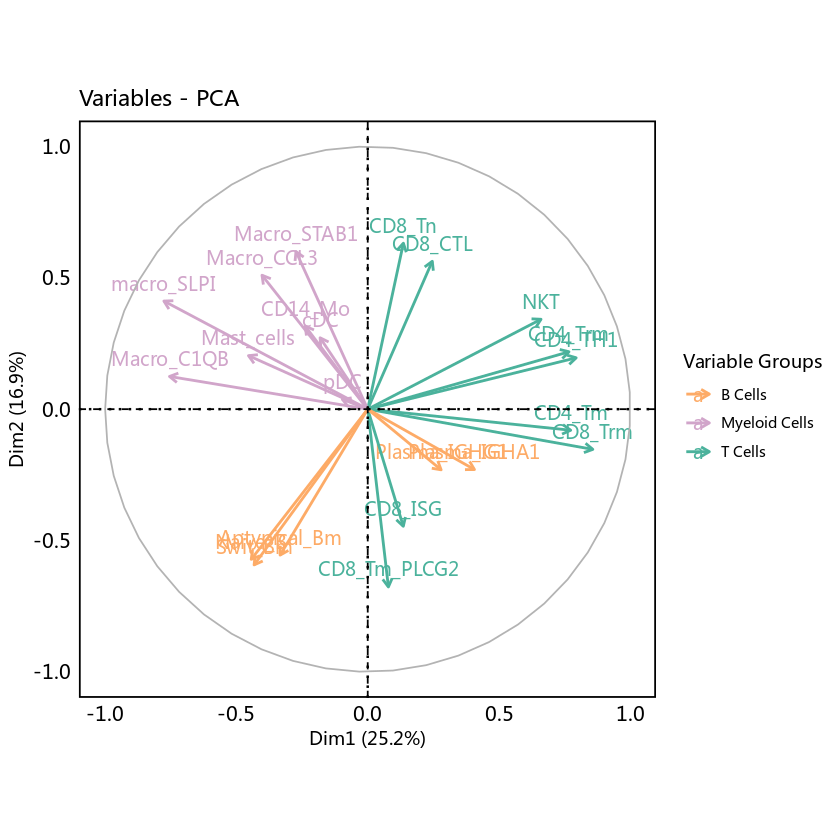

In [21]:
#Myeloid cells, Lymphoid cells
wanted_elements <- c(
'CD14_Mo','cDC','macro_SLPI','pDC','Macro_C1QB','Macro_CCL3','Macro_STAB1','Mast_cells')
indexes <- match(wanted_elements, colnames(pca_data))
indexes <- indexes[!is.na(indexes)]
variable_groups[indexes] <- "Myeloid Cells"

wanted_elements2 <- c('CD4_TH1','CD4_Tm','CD4_Trm','CD8_CTL','CD8_ISG','CD8_Tm_PLCG2','CD8_Tn','CD8_Trm','NKT')
indexes2 <- match(wanted_elements2, colnames(pca_data))
indexes2 <- indexes2[!is.na(indexes2)]
variable_groups[indexes2] <- "T Cells"

wanted_elements3 <- c('Naive_B','Plasma_IGHA1','Plasma_IGHG1','Swit_Bm','Aptypical_Bm')
indexes3 <- match(wanted_elements3, colnames(pca_data))
indexes3 <- indexes3[!is.na(indexes3)]
variable_groups[indexes3] <- "B Cells"

arrow_size <- 0.8
fviz_pca_var(pca_result, col.var = variable_groups, 
             palette = c(  'B Cells' = "#fdab67",          
    'T Cells' = '#4BB29C', 
    'Myeloid Cells' = "#D1A5CA" ),
             arrowsize = arrow_size,
             legend.title = "Variable Groups",
             label = , addEllipses = FALSE) +
  theme_minimal() +
  geom_vline(xintercept = 0, linetype = "dotted", color = "black", size = 0.7) +
  geom_hline(yintercept = 0, linetype = "dotted", color = "black", size = 0.7) +
  theme(
     panel.grid.major = element_blank(), # 去除主网格线
    panel.grid.minor = element_blank(), # 去除副网格线
    panel.grid.minor.x = element_blank(), # X軸の細い補助線を消去
    panel.grid.minor.y = element_blank(), # Y軸の細い補助線を消去
    axis.text.x = element_text(size = 12, color = "black"), # X軸の数値のフォントサイズ
    axis.text.y = element_text(size = 12, color = "black") ,# Y軸の数値のフォントサイズ
      panel.border = element_rect(color = "black", size = 1, linetype = "solid", fill = NA) # 添加黑色实线边框
  )

ggsave("/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio/PCA_CELL_ratio_celltype.pdf", width = 10, height = 9)
ggsave("/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio/PCA_CELL_ratio_celltype.tiff", width = 10, height = 9)


In [22]:
head(df_wide)

,sample,group_A,Aptypical_Bm,CD14_Mo,CD4_TH1,CD4_Tm,CD4_Trm,CD8_CTL,CD8_ISG,CD8_Tm_PLCG2,⋯,Macro_STAB1,Mast_cells,NKT,Naive_B,Plasma_IGHA1,Plasma_IGHG1,Swit_Bm,cDC,macro_SLPI,pDC
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HNM04,HNM04,MAR,0.048153343,0.02290790,0.005610098,0.03927069,0.03132305,0.04347826,0.007480131,0.3132305,⋯,0.0014025245,0.009350164,0.02150538,0.0088826554,0.0004675082,0.022440393,0.071996260,0.032258065,0.05002338,0.0032725573
HNM05,HNM05,MAR,NA,NA,0.002005616,0.03289210,0.01163257,0.05776173,0.029281990,0.5515443,⋯,0.0008022463,0.001604493,0.01484156,NA,NA,0.003610108,0.003610108,0.003610108,0.01805054,NA
HNM07,HNM07,MAR,0.024072217,0.01855567,0.018054162,0.05215647,0.08726179,0.03610832,0.011534604,0.2878636,⋯,0.0005015045,0.013540622,0.03660983,0.0010030090,0.0100300903,0.029588766,0.016048144,0.001003009,0.02457372,NA
HNM09,HNM09,NAR,0.133653846,0.02788462,0.002884615,0.01826923,0.01730769,0.03942308,0.002884615,0.2721154,⋯,0.0009615385,0.001923077,0.01057692,0.0192307692,NA,0.005769231,0.161538462,0.005769231,0.09423077,0.0009615385
HNM10,HNM10,NAR,0.002187227,0.23709536,0.006124234,0.02143482,0.02318460,0.06649169,0.014435696,0.3132108,⋯,0.0004374453,0.002624672,0.01312336,0.0004374453,NA,0.003062117,0.005686789,0.004811899,0.06299213,0.0017497813
HNM14,HNM14,MAR,0.011834320,0.04378698,0.003550296,0.03668639,0.02130178,0.06390533,NA,0.3585799,⋯,0.0118343195,0.046153846,0.02485207,NA,NA,0.009467456,0.028402367,0.033136095,0.06153846,NA


In [23]:
pca_data <- df_wide[, -1]
pca_data <- pca_data[, -1]
pca_data[is.na(pca_data)] <- 0
pca_result <- PCA(pca_data, scale.unit=TRUE, ncp=5)
pca_scores <- as.data.frame(pca_result$ind$coord[, c(1, 2)])

In [31]:
groups <- df_wide[, 2]
groups

[1] "MAR" "MAR" "MAR" "NAR" "NAR" "MAR" "NAR" "SAR" "NAR" "MAR" "NAR" "NAR"
[13] "SAR" "MAR" "MAR" "MAR" "SAR" "NAR" "PAR" "NAR" "SAR" "SAR" "SAR"

In [32]:
names(pca_scores) <- c("Dim1", "Dim2")
pca_scores$Group <- groups

In [33]:
names(pca_scores) <- c("Dim1", "Dim2")
pca_scores$Group <- groups

desired_order <- c("NAR", "SAR", "PAR", "MAR")
pca_scores$Group <- factor(pca_scores$Group, levels = desired_order)
group_colors <- c("NAR" = "#a8a9cb", "SAR" = "#f3b669", "PAR" = "#eee934", "MAR" = "#d74401")

contributions <- pca_result$eig[, 2]
xlab <- paste("PC1 (", round(contributions[1], 2), "%)", sep="")
ylab <- paste("PC2 (", round(contributions[2], 2), "%)", sep="")
group_means <- aggregate(cbind(Dim1, Dim2) ~ Group, data = pca_scores, FUN = mean)

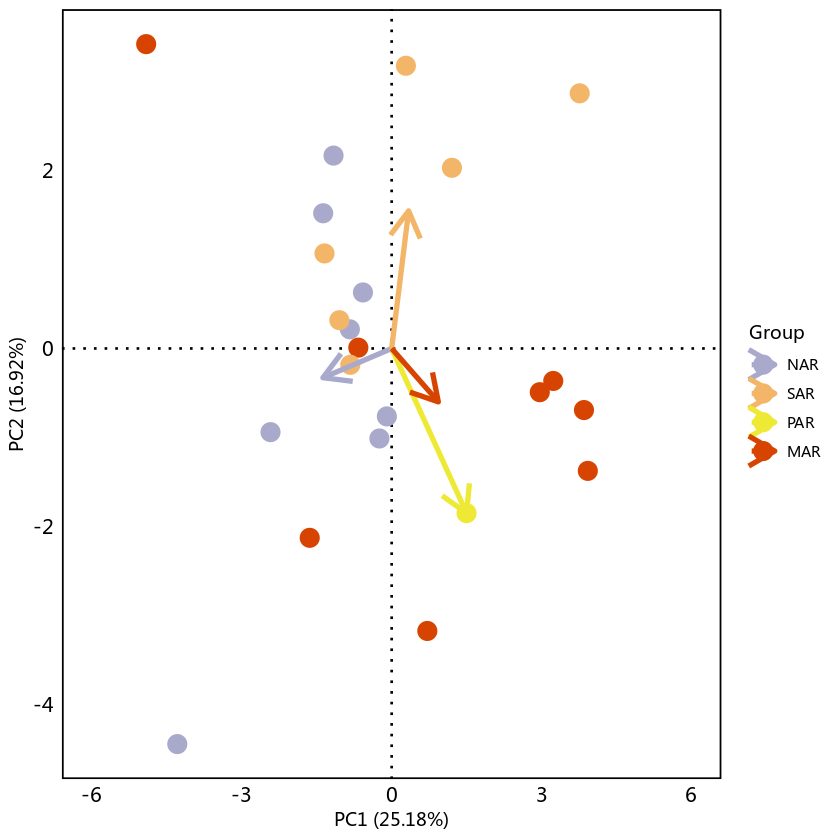

In [34]:


ggplot(pca_scores, aes(x = Dim1, y = Dim2, color = Group)) +
  geom_vline(xintercept = 0, linetype = "dotted", color = "black", size = 0.75) +  # 先にX軸の主軸を描画
  geom_hline(yintercept = 0, linetype = "dotted", color = "black", size = 0.75) +  # 先にY軸の主軸を描画
  geom_point(size = 5) +  # 点をプロット
  geom_segment(data = group_means, aes(xend = Dim1, yend = Dim2, x = 0, y = 0, color = Group), arrow = arrow(), size = 1.5) +  # 矢印を追加
  scale_color_manual(values = group_colors) +
  labs(x = xlab, y = ylab, color = "Group") +
  theme_minimal() +
  theme(
      panel.grid.major = element_blank(), # 去除主网格线
    panel.grid.minor = element_blank(), # 去除副网格线
    panel.grid.minor.x = element_blank(), # X軸の細い補助線を消去
    panel.grid.minor.y = element_blank(), # Y軸の細い補助線を消去
    axis.text.x = element_text(size = 12, color = "black"), # X軸の数値のフォントサイズ
    axis.text.y = element_text(size = 12, color = "black") ,# Y軸の数値のフォントサイズ
      panel.border = element_rect(color = "black", size = 1, linetype = "solid", fill = NA) # 添加黑色实线边框
  ) +
  scale_x_continuous(limits = c(-6, 6)) # 设置 X 轴范围为 -6 到 6

ggsave("/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio/PCA_CELL_ratio_group_a.pdf", width = 10, height = 9)
ggsave("/media/AnalysisTempDisk2/Wuyisha/HNM_IMMUNE/ArchR/Downstream/Cell_ratio/PCA_CELL_ratio_group_a.tiff", width = 10, height = 9)